# 09 -- Randomized bias-validation suite: results

This notebook reads the CSVs produced by `dev_notes/validation_suite/sweep.py` and
plots them in one standardized way, for any swept axis.

## Why this notebook exists

Earlier ad-hoc testing (`temp_testing.ipynb`) surfaced a real finding: **the
`(V, sigma, h3, h4)` parameters that define a truncated Gauss-Hermite series are
not the same thing as that curve's own mean/std/skewness/kurtosis** -- they
coincide only as `h3, h4 -> 0`. Measured directly, with **zero clipping and zero
fitting involved**:

```
V=100, sigma=200, h3=0.03, h4=0.00  ->  true curve mean  = 109.7 km/s   (nominal: 100)
V=100, sigma=200, h3=0.00, h4=0.05  ->  true curve sigma = 219 km/s     (nominal: 200)
```

Over this suite's `wide` preset (sigma 40-400, h3/h4 in +/-0.1), **53% of random
draws** have `|V shift| > 10 km/s` and **68%** have `|sigma shift| > 5%` from this
effect alone -- before any noise or fitting. Even the `safe` preset (h3/h4
+/-0.05) still has 22%/46%. Clipping (the curve going negative and being
clamped) is a real, separate, smaller effect on top of this (a few percent of
mass at the extremes of the range).

**The consequence:** nominal generator parameters are never a valid "truth" to
score fitting bias against once h3/h4 leave a narrow neighborhood of zero. Every
row produced by this suite carries BOTH the nominal parameters and the
truth-curve's own measured moments (`truth_v/sigma/h3/h4`, from
`compute_losvd_moments` on the actual discretized, clipped, normalized curve),
plus a `gen_mismatch_*` diagnostic (truth minus nominal). **All bias numbers
below are `fit - truth`, never `fit - nominal`.** See
`dev_notes/validation_suite/FINDINGS.md` for the full writeup, and
`mocks.py`'s module docstring for the mechanism.

## How the suite is built

- `mocks.py` -- mock generation (GH-based and an alternative spline-based
  truth generator), the generator-mismatch diagnostic, clipping diagnostics.
- `runner.py` -- fits one mock case, returns one standardized result row.
- `sweep.py` -- CLI: fix one named axis over a grid, randomize every other axis
  fresh per replicate, write rows to CSV incrementally. Reproducible given the
  same `--seed`; "randomized" refers to independent draws across replicates,
  not lack of reproducibility.

Each swept axis is its own CSV; this notebook loads whichever are present.


In [1]:
from __future__ import annotations
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "../../dev_notes/validation_suite/results"  # this notebook lives in dev_notes/scratch_notebooks/

def load_sweep(name):
    path = os.path.join(RESULTS_DIR, name)
    if not os.path.exists(path):
        print(f"(missing: {name} -- run sweep.py to generate it)")
        return None
    df = pd.read_csv(path)
    print(f"{name}: {len(df)} rows, axis={df['sweep_axis'].iloc[0]}, "
          f"values={sorted(df['sweep_value'].unique())}")
    return df

available = sorted(os.path.basename(p) for p in glob.glob(os.path.join(RESULTS_DIR, "sweep_*.csv")))
print("available sweep files:", available)


available sweep files: ['sweep_h3_night2.csv', 'sweep_h3_safe.csv', 'sweep_h3_safe_STALE_pre2026-07-30-fixes.csv', 'sweep_h4_night2.csv', 'sweep_h4_safe.csv', 'sweep_h4_safe_STALE_pre2026-07-30-fixes.csv', 'sweep_sigma_gaussian.csv', 'sweep_sigma_gaussian_STALE_pre2026-07-30-fixes.csv', 'sweep_sigma_night2.csv', 'sweep_sigma_safe.csv', 'sweep_sigma_safe_STALE_pre2026-07-30-fixes.csv', 'sweep_sigma_spline.csv', 'sweep_sigma_spline_STALE_pre2026-07-30-fixes.csv', 'sweep_snr_night2.csv', 'sweep_snr_safe.csv', 'sweep_snr_safe_STALE_pre2026-07-30-fixes.csv', 'sweep_snr_spline.csv', 'sweep_snr_spline_STALE_pre2026-07-30-fixes.csv']


## Standardized plotting

One function, reused for every sweep: top row is **fit bias** (recovered minus
truth curve) for V/sigma/h3/h4 vs. the swept axis, with the median and an IQR
band across randomized replicates. Bottom row is the **generator mismatch**
(truth curve minus nominal) for the same four quantities, on axes chosen to be
comparable to the top row -- so it is visually immediate whether an apparent
trend in the top row is a real fitting effect or an artifact of the generator,
which was exactly the ambiguity that motivated building this.


In [2]:
def _band(ax, x, y, color, label):
    order = np.argsort(x)
    xs = np.asarray(x)[order]; ys = np.asarray(y)[order]
    ux = np.unique(xs)
    med = np.array([np.median(ys[xs == v]) for v in ux])
    q25 = np.array([np.percentile(ys[xs == v], 25) for v in ux])
    q75 = np.array([np.percentile(ys[xs == v], 75) for v in ux])
    ax.plot(ux, med, 'o-', color=color, lw=1.8, label=label)
    ax.fill_between(ux, q25, q75, color=color, alpha=0.18, lw=0)
    ax.scatter(xs, ys, color=color, s=10, alpha=0.25, zorder=1)

def plot_sweep(df, axis_label=None, title=None):
    axis_label = axis_label or df['sweep_axis'].iloc[0]
    x = df['sweep_value']
    fig, axes = plt.subplots(2, 4, figsize=(19, 7.5), sharex=True)
    fit_cols = [('bias_v', 'V bias (km/s)'), ('bias_sigma', 'sigma bias (km/s)'),
                ('bias_h3', 'h3 bias'), ('bias_h4', 'h4 bias')]
    gen_cols = [('gen_mismatch_dv', 'V mismatch (km/s)'), ('gen_mismatch_dsigma', 'sigma mismatch (km/s)'),
                ('gen_mismatch_dh3', 'h3 mismatch'), ('gen_mismatch_dh4', 'h4 mismatch')]
    for j, (col, lab) in enumerate(fit_cols):
        ax = axes[0, j]
        _band(ax, x, df[col], 'seagreen', 'fit bias (vs. truth curve)')
        ax.axhline(0, color='0.5', lw=0.8)
        ax.set_title(lab, fontsize=10); ax.grid(alpha=0.25)
        if j == 0: ax.set_ylabel('recovered - truth')
    for j, (col, lab) in enumerate(gen_cols):
        ax = axes[1, j]
        _band(ax, x, df[col], 'tab:orange', 'generator mismatch (truth vs. nominal)')
        ax.axhline(0, color='0.5', lw=0.8)
        ax.set_title(lab, fontsize=10); ax.grid(alpha=0.25)
        ax.set_xlabel(f'nominal {axis_label} (swept)')
        if j == 0: ax.set_ylabel('truth - nominal')
    axes[0, 0].legend(fontsize=8, loc='best')
    axes[1, 0].legend(fontsize=8, loc='best')
    fig.suptitle(title or f'Sweep: {axis_label}  (top: fit bias vs. truth curve  |  bottom: generator mismatch vs. nominal)',
                 fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()
    print(f"n={len(df)}  success rate={df['success'].mean()*100:.0f}%  "
          f"median |clipped_mass_frac|={df['clipped_mass_frac'].abs().median()*100:.3f}%  "
          f"lam_used values seen: {sorted(df['lam_used'].unique())}")


## Sigma sweep (safe preset, h3/h4 +/-0.05, S/N 20-400 randomized)


sweep_sigma_safe.csv: 90 rows, axis=sigma, values=[np.float64(40.0), np.float64(80.0), np.float64(140.0), np.float64(220.0), np.float64(300.0), np.float64(400.0)]


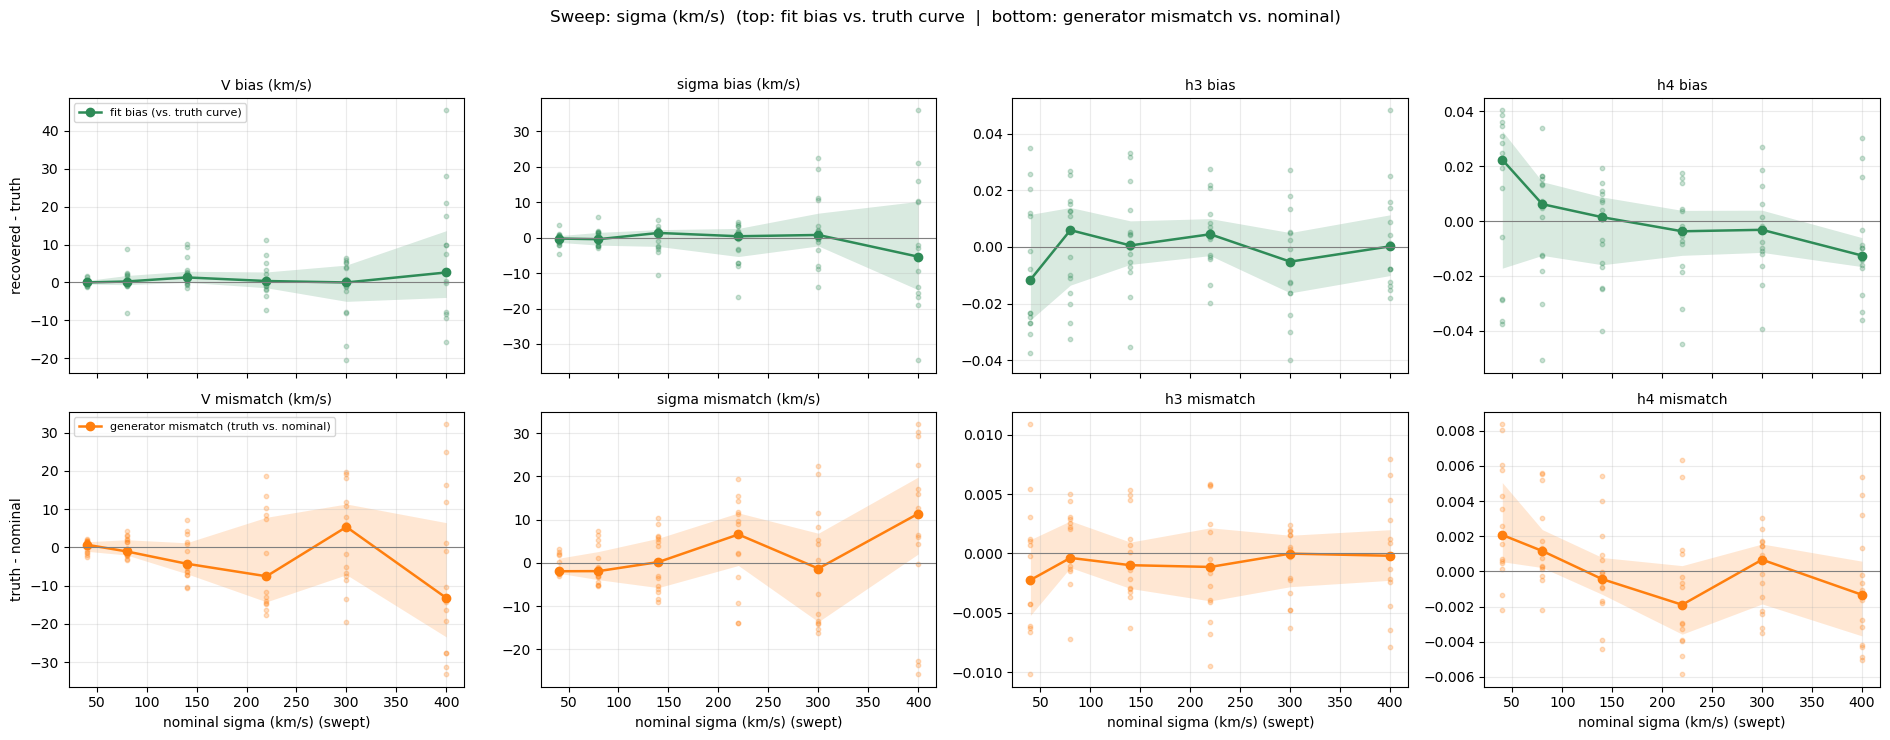

n=90  success rate=100%  median |clipped_mass_frac|=0.000%  lam_used values seen: [np.float64(1.0), np.float64(8.0), np.float64(64.0), np.float64(512.0), np.float64(4096.0), np.float64(32768.0)]


In [3]:
df_sigma = load_sweep("sweep_sigma_safe.csv")
if df_sigma is not None:
    plot_sweep(df_sigma, axis_label="sigma (km/s)")


## S/N sweep (safe preset, sigma 40-300 and h3/h4 +/-0.05 randomized)


sweep_snr_safe.csv: 120 rows, axis=snr, values=[np.float64(20.0), np.float64(40.0), np.float64(60.0), np.float64(100.0), np.float64(150.0), np.float64(200.0), np.float64(300.0), np.float64(400.0)]


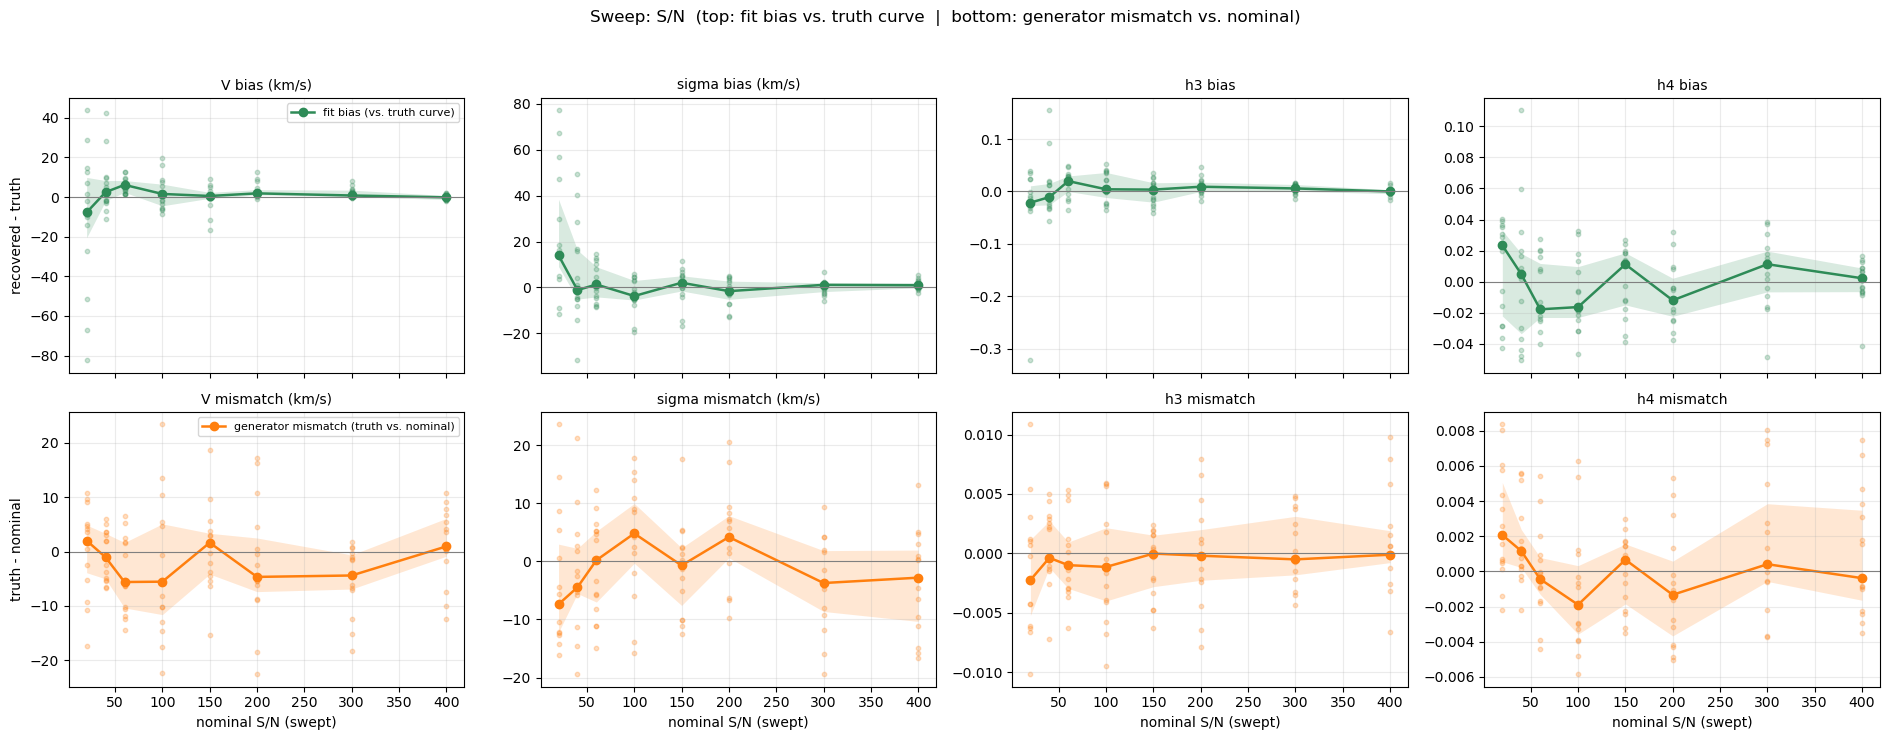

n=120  success rate=100%  median |clipped_mass_frac|=0.003%  lam_used values seen: [np.float64(1.0), np.float64(8.0), np.float64(64.0), np.float64(512.0), np.float64(4096.0), np.float64(32768.0)]


In [4]:
df_snr = load_sweep("sweep_snr_safe.csv")
if df_snr is not None:
    plot_sweep(df_snr, axis_label="S/N")


## h3 sweep (safe preset, sigma/S-N/h4 randomized)


sweep_h3_safe.csv: 75 rows, axis=h3, values=[np.float64(-0.08), np.float64(-0.04), np.float64(0.0), np.float64(0.04), np.float64(0.08)]


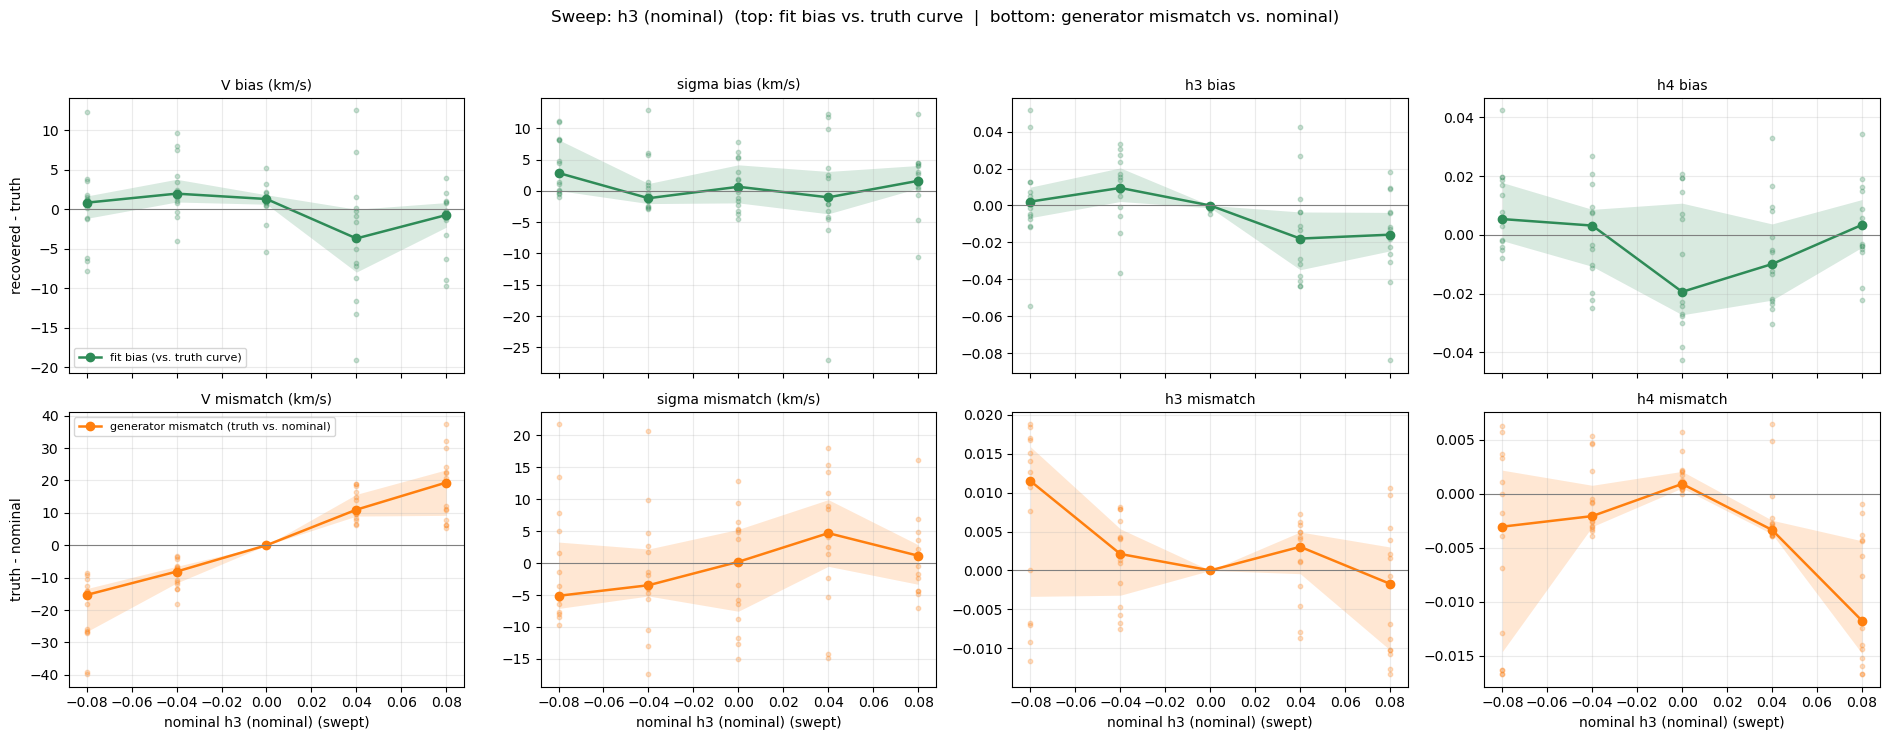

n=75  success rate=100%  median |clipped_mass_frac|=0.127%  lam_used values seen: [np.float64(1.0), np.float64(8.0), np.float64(64.0), np.float64(512.0), np.float64(4096.0), np.float64(32768.0)]


In [5]:
df_h3 = load_sweep("sweep_h3_safe.csv")
if df_h3 is not None:
    plot_sweep(df_h3, axis_label="h3 (nominal)")


## h4 sweep (safe preset, sigma/S-N/h3 randomized)


sweep_h4_safe.csv: 75 rows, axis=h4, values=[np.float64(-0.08), np.float64(-0.04), np.float64(0.0), np.float64(0.04), np.float64(0.08)]


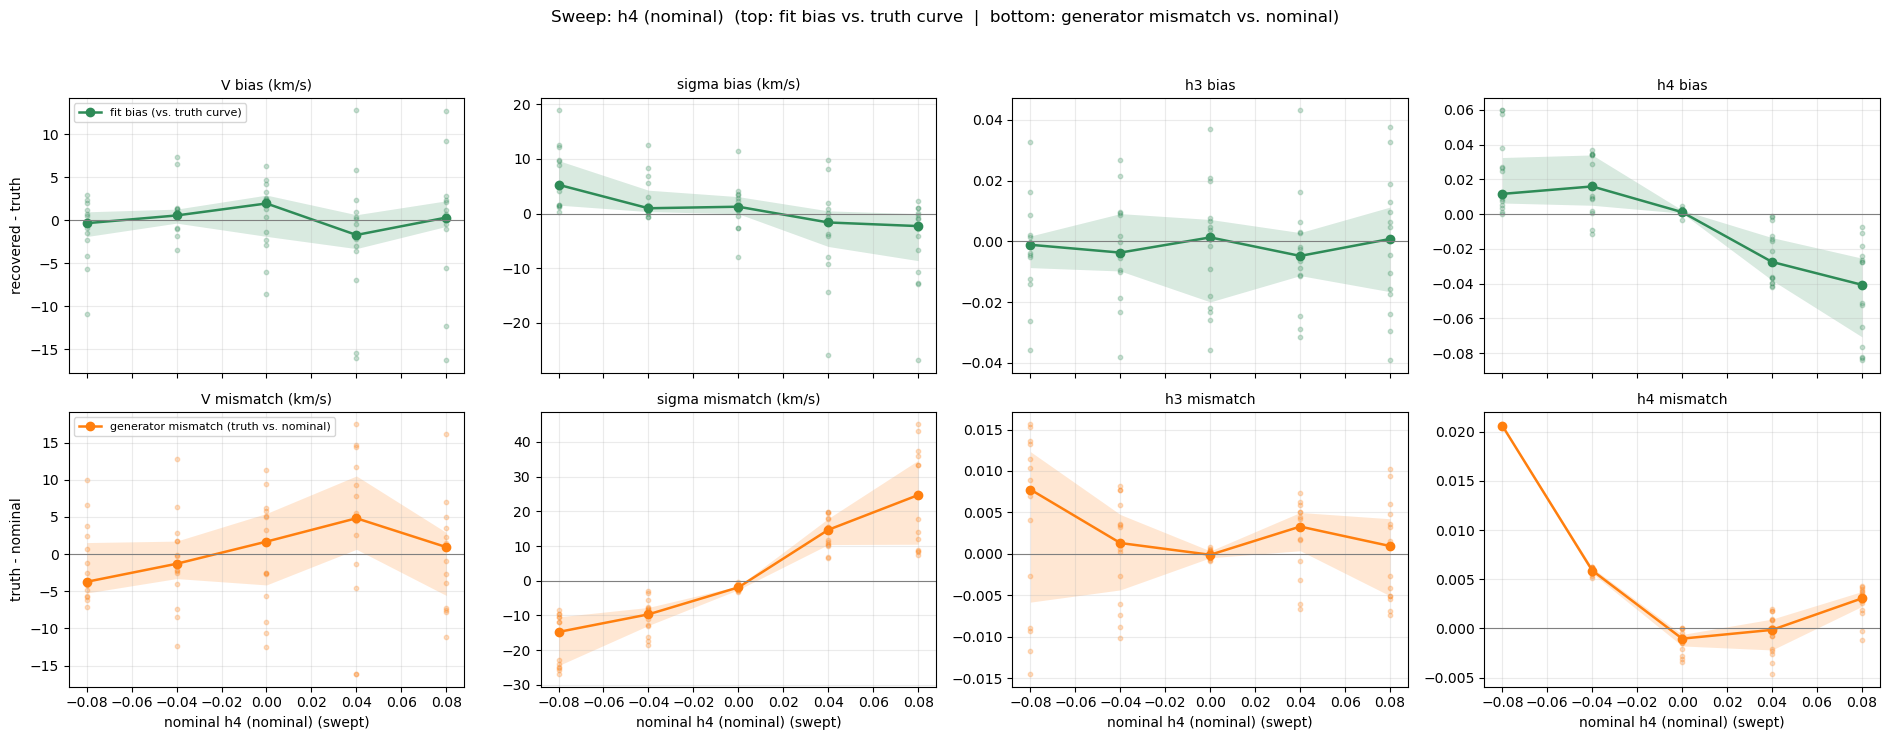

n=75  success rate=100%  median |clipped_mass_frac|=0.006%  lam_used values seen: [np.float64(1.0), np.float64(8.0), np.float64(64.0), np.float64(512.0), np.float64(4096.0), np.float64(32768.0)]


In [6]:
df_h4 = load_sweep("sweep_h4_safe.csv")
if df_h4 is not None:
    plot_sweep(df_h4, axis_label="h4 (nominal)")


## Control: pure-Gaussian sigma sweep (h3=h4=0 by construction)

This isolates sigma-recovery bias with the generator-mismatch mechanism above
switched off entirely (`gaussian_only=True` forces `h3=h4=0`, so `gen_mismatch_*`
is exactly zero by construction here -- any bias in this panel is not
attributable to the GH-parameterization effect at all). Compare directly to
the sigma sweep above: if the two look similar, sigma bias is dominated by the
fitting method itself; if the full-shape sweep is visibly worse, the
generator-mismatch mechanism (or the h3/h4 shrinkage it interacts with) is
doing real work.


sweep_sigma_gaussian.csv: 90 rows, axis=sigma, values=[np.float64(40.0), np.float64(80.0), np.float64(140.0), np.float64(220.0), np.float64(300.0), np.float64(400.0)]


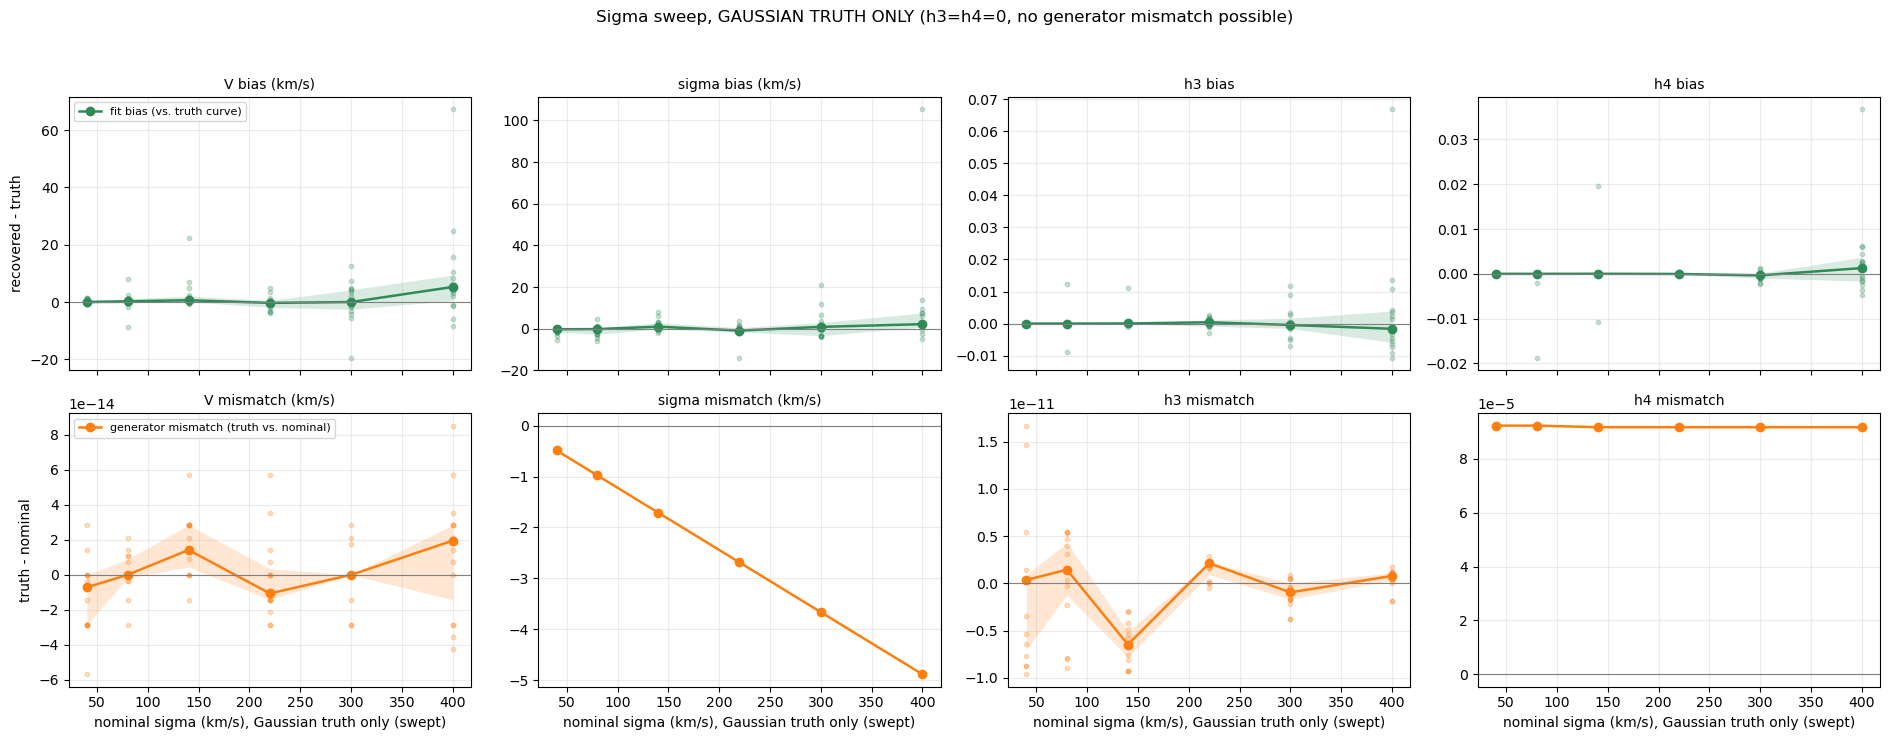

n=90  success rate=99%  median |clipped_mass_frac|=0.000%  lam_used values seen: [np.float64(8.0), np.float64(64.0), np.float64(512.0), np.float64(4096.0), np.float64(32768.0)]


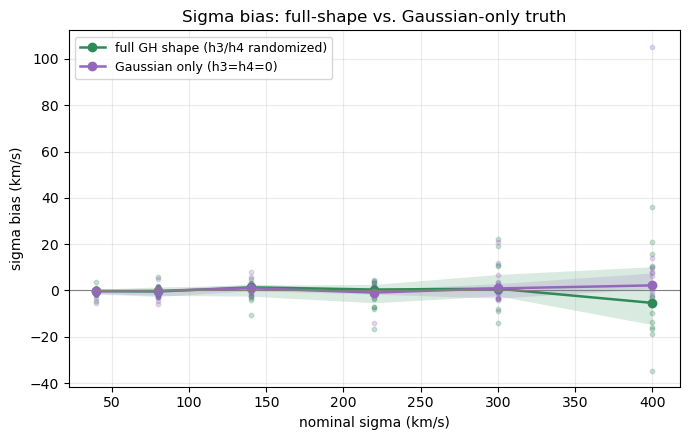

In [7]:
df_sigma_gauss = load_sweep("sweep_sigma_gaussian.csv")
if df_sigma_gauss is not None:
    plot_sweep(df_sigma_gauss, axis_label="sigma (km/s), Gaussian truth only",
               title="Sigma sweep, GAUSSIAN TRUTH ONLY (h3=h4=0, no generator mismatch possible)")

if df_sigma is not None and df_sigma_gauss is not None:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    _band(ax, df_sigma['sweep_value'], df_sigma['bias_sigma'], 'seagreen', 'full GH shape (h3/h4 randomized)')
    _band(ax, df_sigma_gauss['sweep_value'], df_sigma_gauss['bias_sigma'], 'tab:purple', 'Gaussian only (h3=h4=0)')
    ax.axhline(0, color='0.5', lw=0.8); ax.set_xlabel('nominal sigma (km/s)'); ax.set_ylabel('sigma bias (km/s)')
    ax.set_title('Sigma bias: full-shape vs. Gaussian-only truth'); ax.legend(fontsize=9); ax.grid(alpha=0.25)
    plt.tight_layout(); plt.show()


## GH truth vs. spline truth: does the generator family itself matter?

This is the direct empirical answer to "should we stop using Gauss-Hermite
truths for bias testing?" Both sweeps below use the identical fitter, grid of
nominal sigma/S-N values, replicate count, and randomization of everything
else -- the *only* difference is whether the truth LOSVD is a GH curve (with
its own well-characterized generator-mismatch, scored correctly against its
own moments) or a curve defined directly as `exp(spline)` with no GH step at
all (`mocks.build_spline_truth`, swept via `wiggle_scale` in place of h3/h4).

If fitting bias is comparable between the two, the GH-truth generator was
never the problem -- only scoring bias against *nominal* GH parameters was.
If the spline-truth sweep shows meaningfully smaller/cleaner bias, that is
real evidence GH shapes are intrinsically harder for this fitter to recover
(plausible: GH corrections put mass in specific shoulder/tail structures a
smoothness penalty may resist differently than an arbitrary smooth wiggle
does), and spline truths should become the default tool for isolating pure
fitting/regularization bias -- while GH truths remain the right choice
whenever the question is literally "how well do we recover realistic,
literature-comparable GH moments," since that is what downstream orbit-
superposition modeling and other codes actually consume.


sweep_sigma_spline.csv: 90 rows, axis=sigma, values=[np.float64(40.0), np.float64(80.0), np.float64(140.0), np.float64(220.0), np.float64(300.0), np.float64(400.0)]


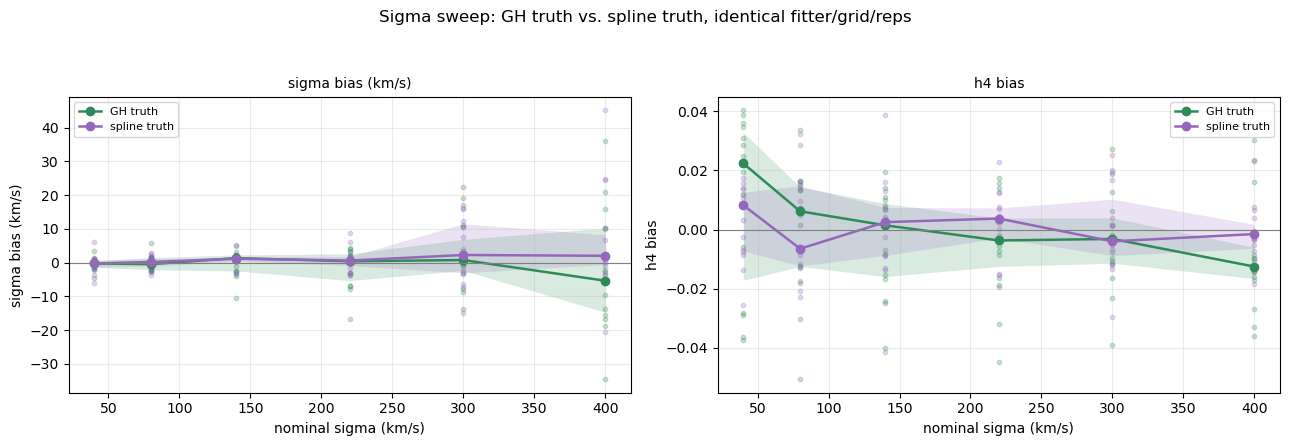

median |sigma bias|: GH truth = 2.38 km/s   spline truth = 1.92 km/s
sweep_snr_spline.csv: 120 rows, axis=snr, values=[np.float64(20.0), np.float64(40.0), np.float64(60.0), np.float64(100.0), np.float64(150.0), np.float64(200.0), np.float64(300.0), np.float64(400.0)]


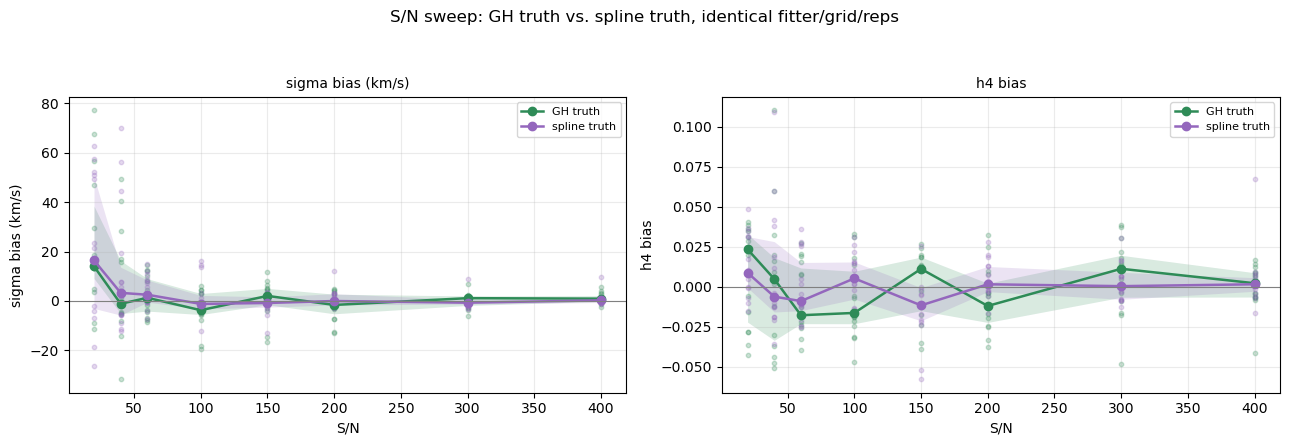

median |sigma bias|: GH truth = 4.45 km/s   spline truth = 2.98 km/s


In [8]:
df_sigma_spline = load_sweep("sweep_sigma_spline.csv")
if df_sigma is not None and df_sigma_spline is not None:
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for col, lab, a in [('bias_sigma', 'sigma bias (km/s)', ax[0]), ('bias_h4', 'h4 bias', ax[1])]:
        _band(a, df_sigma['sweep_value'], df_sigma[col], 'seagreen', 'GH truth')
        _band(a, df_sigma_spline['sweep_value'], df_sigma_spline[col], 'tab:purple', 'spline truth')
        a.axhline(0, color='0.5', lw=0.8); a.set_xlabel('nominal sigma (km/s)'); a.set_ylabel(lab)
        a.set_title(lab, fontsize=10); a.legend(fontsize=8); a.grid(alpha=0.25)
    fig.suptitle('Sigma sweep: GH truth vs. spline truth, identical fitter/grid/reps', fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()
    gh_med = df_sigma['bias_sigma'].abs().median(); sp_med = df_sigma_spline['bias_sigma'].abs().median()
    print(f"median |sigma bias|: GH truth = {gh_med:.2f} km/s   spline truth = {sp_med:.2f} km/s")

df_snr_spline = load_sweep("sweep_snr_spline.csv")
if df_snr is not None and df_snr_spline is not None:
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for col, lab, a in [('bias_sigma', 'sigma bias (km/s)', ax[0]), ('bias_h4', 'h4 bias', ax[1])]:
        _band(a, df_snr['sweep_value'], df_snr[col], 'seagreen', 'GH truth')
        _band(a, df_snr_spline['sweep_value'], df_snr_spline[col], 'tab:purple', 'spline truth')
        a.axhline(0, color='0.5', lw=0.8); a.set_xlabel('S/N'); a.set_ylabel(lab)
        a.set_title(lab, fontsize=10); a.legend(fontsize=8); a.grid(alpha=0.25)
    fig.suptitle('S/N sweep: GH truth vs. spline truth, identical fitter/grid/reps', fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()
    gh_med = df_snr['bias_sigma'].abs().median(); sp_med = df_snr_spline['bias_sigma'].abs().median()
    print(f"median |sigma bias|: GH truth = {gh_med:.2f} km/s   spline truth = {sp_med:.2f} km/s")


## Diagnostics: how often does lambda selection do something unexpected?

Per the noise-floor and lambda-instability findings elsewhere in this project
(`dev_notes/ghcore/FINDINGS.md`, notebook 02 Section 6), adaptive lambda
selection can flip between very different grid values across noise seeds at
moderate S/N, because the AIC criterion goes flat. This panel shows the
selected lambda's spread at each swept value, across all currently-loaded
sweeps, to flag whether that instability shows up broadly or is confined to a
narrow regime.


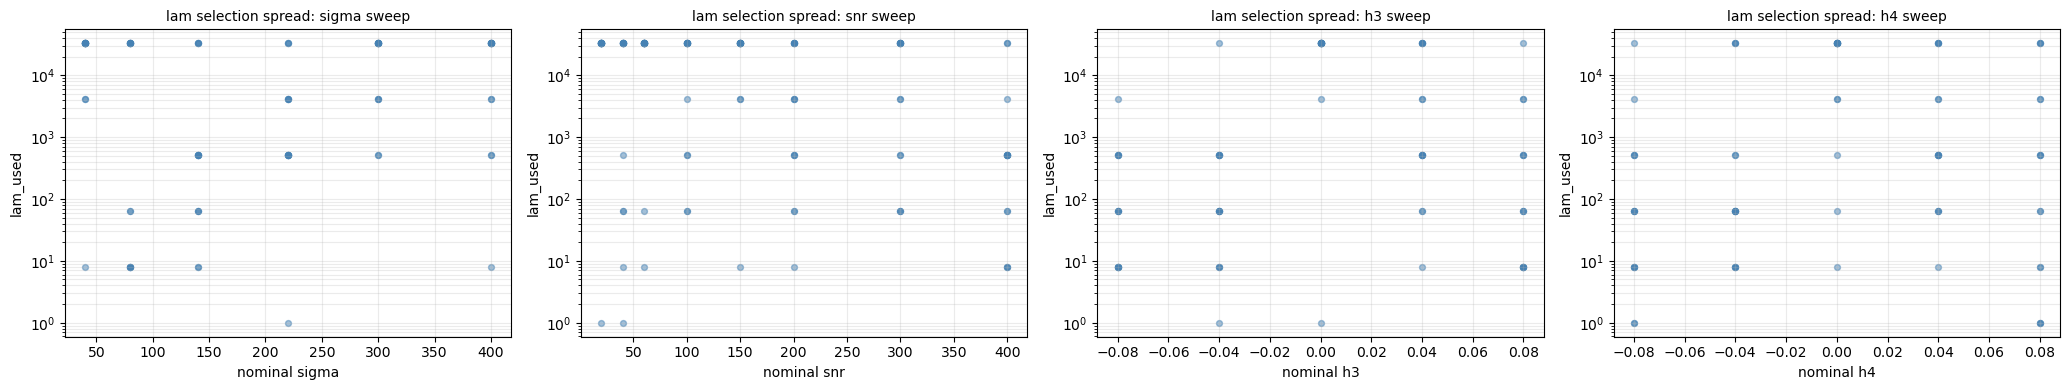

In [9]:
dfs = {name: df for name, df in
       [("sigma", df_sigma), ("snr", df_snr), ("h3", df_h3), ("h4", df_h4)] if df is not None}
if dfs:
    fig, axes = plt.subplots(1, len(dfs), figsize=(5.2 * len(dfs), 4))
    if len(dfs) == 1: axes = [axes]
    for ax, (name, df) in zip(axes, dfs.items()):
        for val in sorted(df['sweep_value'].unique()):
            lam = df.loc[df['sweep_value'] == val, 'lam_used']
            ax.scatter([val] * len(lam), lam, alpha=0.5, s=18, color='steelblue')
        ax.set_yscale('log'); ax.set_xlabel(f'nominal {name}'); ax.set_ylabel('lam_used')
        ax.set_title(f'lam selection spread: {name} sweep', fontsize=10); ax.grid(alpha=0.25, which='both')
    plt.tight_layout(); plt.show()


## Extending this suite

- **New single-axis sweep:** `python sweep.py --axis <v|sigma|h3|h4|snr> --values ... --n-reps ... --out results/<name>.csv`,
  then add a `load_sweep`/`plot_sweep` pair above.
- **A 2D combination** (e.g. sigma x S/N jointly, to look for interaction
  effects rather than one-axis-at-a-time bias): pass `fixed={"sigma": s, "snr": n}`
  directly to `runner.run_one` in a small custom loop -- `sweep.py`'s `--axis`
  flag is deliberately single-axis for now; a `--axis2`/`--values2` pair is the
  natural extension once single-axis results are trusted.
- **Spline-truth sweeps:** `--truth-kind spline` (see the comparison section
  above) -- sweep `--axis wiggle_scale` for the shape-randomization knob in
  place of h3/h4.
- **Wide-preset stress runs:** pass `--preset wide` to any sweep to probe the
  h3/h4 +/-0.1 regime directly -- expect the bottom (generator-mismatch) row to
  dominate the top row almost everywhere; that is the expected, already-measured
  behavior, not a new bug.
